![Banner](images/09_distributed_spatial_datas.png)

# Shortest Paths, Centrality and Accessibility on Large Road Networks

Straight-line distance is a poor guide to how far people actually travel: rivers, railways and
the shape of a street grid force detours. Network analysis measures distances along roads, finds
the routes through which most trips pass, and reveals parts of a network that cannot reach each
other. These problems are graph problems, and some of them (betweenness centrality in particular)
grow much faster than the size of the network. This notebook builds a graph of the 22,813 road
segments of Wichita, Kansas, with `geolattice.distributed.network`, computes travel times from
every building to the nearest school, finds the busiest junctions with betweenness centrality on
the CPU (SciPy, NetworkX) and the GPU (cuGraph), and shows when GeoLattice deliberately falls back
to the CPU.

## Overview

### From lines to a graph

A road network is a graph: **nodes** are junctions and dead ends, **edges** are the road segments
between them, each with a **weight** (length, or travel time). Turning lines into a graph needs
the lines to be **noded**: two roads are connected only where they share an end point. OSMnx
delivers noded, simplified networks; raw line data (a shapefile of roads) often needs noding and
snapping of end points that almost meet.

### The costs of the common questions

| Question | Algorithm | Cost for `n` nodes and `m` edges |
|---|---|---|
| Shortest path from one source | Dijkstra | about `m log n` |
| Distances from many sources (accessibility) | multi-source Dijkstra, or one Dijkstra per source | `sources x m log n` |
| Connected parts of the network | breadth-first search | `n + m` |
| PageRank | power iteration | `iterations x m` |
| **Betweenness centrality** | Brandes: shortest paths from every node | `n x m`, quadratic and more |

Betweenness counts, for each node, the share of all shortest paths that pass through it: the
junctions and bridges that carry through traffic. Exact betweenness of a 16,000 node network
needs 16,000 shortest-path trees. Sampling `k` source nodes gives an unbiased approximation at
`k / n` of the cost.

### Graphs on GPUs

cuGraph runs breadth-first search, single-source shortest paths, PageRank and betweenness on the
GPU. Road networks are a hard case for GPUs: they are sparse, nearly planar and have long
shortest paths, so each step of a search touches few nodes and the GPU's thousands of cores have
little to do at once. GPUs shine on large graphs with short paths (social and web graphs). A
second limit is numerical: Brandes' algorithm counts the shortest paths between nodes, and on
grid-like networks those counts grow exponentially with distance; cuGraph stores them as 64-bit
integers, which overflow on large lattices.

## Network Analysis with GeoLattice

| Function | Returns | CPU / GPU |
|---|---|---|
| `pdist.network.graph_from_lines(lines, weight=, tolerance=)` | a `Graph` (node coordinates, edge arrays) | NumPy |
| `shortest_path(g, source, target)` | nodes, cost and route geometry | SciPy Dijkstra / cuGraph SSSP |
| `shortest_path_lengths(g, sources, cutoff=)` | `(sources, n_nodes)` matrix of costs | SciPy multi-source Dijkstra / cuGraph SSSP per source |
| `centrality(g, kind=, k=)` | betweenness, PageRank or degree per node | NetworkX / cuGraph |
| `components(g)` | component label per node | SciPy / cuGraph |
| `nearest_nodes(g, points)` | nearest node per point | `pdist.vector.knn` |
| `max_shortest_path_count(g)` | a probe for cuGraph's path counter overflow | SciPy |

A `Graph` converts to SciPy (`to_scipy`), cuGraph (`to_cugraph`) and NetworkX (`to_networkx`), and
its nodes to a GeoDataFrame (`nodes_gdf`).

### Learning objectives

1. Build a weighted graph from road lines and check its connectivity.
2. Compute shortest routes and travel times, and compare network with straight-line distance.
3. Measure accessibility (travel time to the nearest school) for every building of a city.
4. Compute betweenness centrality exactly and by sampling, on CPU and GPU, and judge the
   approximation.
5. Explain why road networks suit GPUs less well than other graphs, and when GeoLattice falls
   back to the CPU.

### Data

| Dataset | Content |
|---|---|
| Wichita road network | 22,813 drivable OpenStreetMap road segments (OSMnx, simplified, undirected), EPSG:5070 |
| Wichita schools and hospitals | 171 schools and 12 hospitals from OpenStreetMap |
| Kansas building footprints | the 180,000 buildings inside the road network's extent |

### Contents

- Setup
- A graph from road lines
- Travel time weights and one route
- Accessibility: travel time to the nearest school
- Connected components and what they reveal
- Betweenness centrality on CPU and GPU
- When the GPU is not used
- Summary and exercises

## Setup

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings
import os  # environment and CPU count
import time  # wall-clock timing
from pathlib import Path  # file paths

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import geopandas as gpd  # vector data
import xarray as xr  # labelled rasters

import geolattice  # GeoLattice
import geolattice.distributed as pdist  # distributed and GPU spatial computing
import dist_data as dd  # chapter helper: paths, cached downloads, timers

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
pd.set_option("display.width", 140)  # wider printed tables
OUT = Path("outputs")  # results and scratch files written by this chapter
OUT.mkdir(exist_ok=True)  # create it if needed
caps = pdist.capabilities()  # engines and GPUs on this machine
print("GeoLattice", geolattice.__version__, "|", os.cpu_count(), "CPU cores |", caps["gpus"], "GPU(s)",  # versions
      f"({caps.get('gpu_memory_total', 0) / 1e9:.0f} GB)" if caps["gpus"] else "")  # GPU memory

import warnings as _w  # to show one library warning on purpose
import shapely  # geometry helpers


def sync():  # wait for queued GPU work so timings are real
    if caps["gpus"]:  # only with a GPU
        import cupy as cp  # GPU arrays
        cp.cuda.Device().synchronize()  # block until done


def timed(fn):  # wall time and result of one call
    t = time.perf_counter(); out = fn(); sync(); return time.perf_counter() - t, out  # time it

GeoLattice 0.3.49 | 24 CPU cores | 1 GPU(s) (17 GB)


## A graph from road lines

In [2]:
roads = dd.wichita_roads()  # 22,813 OSM road segments, EPSG:5070
print(f"{len(roads):,} segments, {roads.length.sum() / 1000:,.0f} km of road")  # size
print(roads.highway.value_counts().head(6).to_string())  # road classes
g = pdist.network.graph_from_lines(roads)  # nodes at segment end points, weight = length in metres
print(f"graph: {g.n_nodes:,} nodes, {g.n_edges:,} edges, directed: {g.directed}")  # graph size
deg = pdist.network.centrality(g, "degree")  # edges per node
print("node degree:", deg.value_counts().sort_index().to_dict())  # dead ends, bends, junctions

22,813 segments, 3,435 km of road
highway
residential      15702
secondary         2631
tertiary          2107
unclassified      1345
motorway_link      421
motorway           221
graph: 16,032 nodes, 22,813 edges, directed: False


node degree: {1.0: 3074, 2.0: 663, 3.0: 8603, 4.0: 3640, 5.0: 49, 6.0: 3}


Most nodes are three- and four-way junctions; nodes of degree 1 are dead ends (cul-de-sacs, the
edge of the city limits). OSMnx removes most nodes of degree 2 (mere bends); the few hundred left
mark places where a road's attributes, such as its name or class, change.

## Travel time weights and one route

Length is not what drivers minimize. Each segment gets a speed from its OSM `maxspeed` tag, or a
typical speed for its road class when the tag is missing, and its travel time in minutes becomes
the edge weight.

In [3]:
default_kmh = {"motorway": 105, "motorway_link": 60, "trunk": 90, "primary": 70, "secondary": 60,  # typical speeds by class
               "tertiary": 50, "unclassified": 45, "residential": 40, "living_street": 20}  # km/h
first = lambda h: h.strip("[]").replace("'", "").split(",")[0].strip()  # first class of multi-class segments
mph = pd.to_numeric(roads.maxspeed.str.extract(r"(\d+)")[0], errors="coerce")  # posted speed in mph
roads["kmh"] = (mph * 1.609).fillna(roads.highway.map(first).map(default_kmh)).fillna(40)  # km/h
roads["minutes"] = roads.length / 1000 / roads.kmh * 60  # travel time per segment
gt = pdist.network.graph_from_lines(roads, weight="minutes")  # same nodes, time weights
print(f"posted speed on {mph.notna().mean():.0%} of segments; total driving time over all roads {roads.minutes.sum() / 60:.0f} h")  # coverage

posted speed on 8% of segments; total driving time over all roads 76 h


quickest: 27.2 min over 34.5 km | shortest: 32.6 km | straight line 25.3 km


cuGraph: 27.2 min, same nodes: True


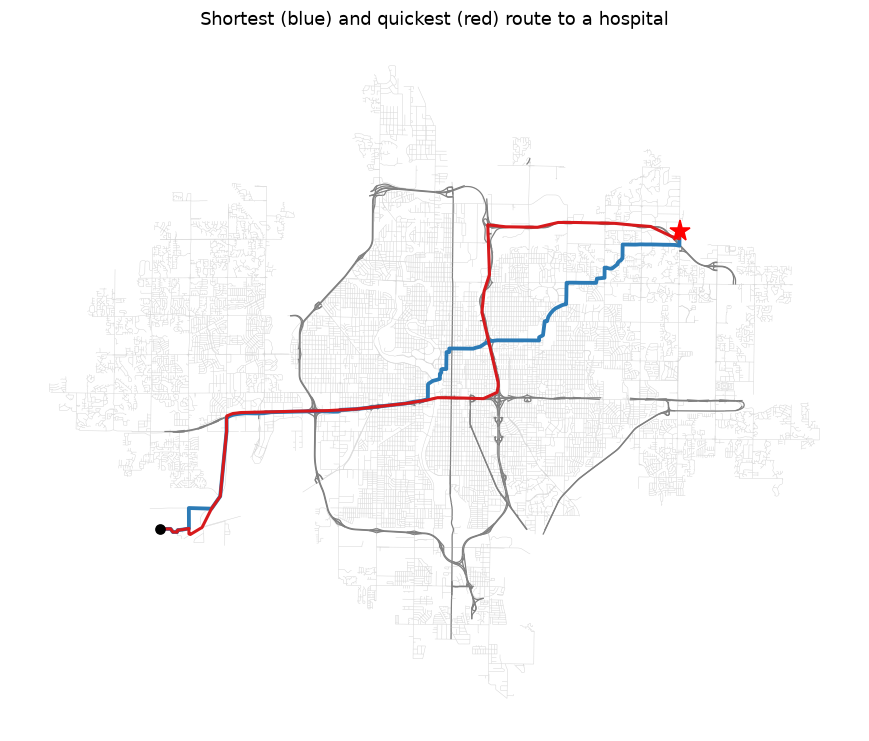

In [4]:
fac = dd.wichita_facilities()  # schools and hospitals
hosp = fac[fac.amenity == "hospital"].reset_index(drop=True)  # 12 hospitals
nodes = gt.nodes_gdf()  # nodes as points
src = int(pdist.network.nearest_nodes(gt, gpd.GeoDataFrame(geometry=[shapely.Point(nodes.total_bounds[[0, 1]] + 3000)], crs=5070))[0])  # a node near the south-west corner
dst = int(pdist.network.nearest_nodes(gt, hosp.iloc[[0]])[0])  # the node nearest the first hospital
fast = pdist.network.shortest_path(gt, src, dst, compute="cpu")  # quickest route
short = pdist.network.shortest_path(g, src, dst, compute="cpu")  # shortest route
crow = float(np.hypot(*(gt.xy[src] - gt.xy[dst])))  # straight line
print(f"quickest: {fast['cost']:.1f} min over {shapely.length(fast['geometry']) / 1000:.1f} km | shortest: {short['cost'] / 1000:.1f} km | straight line {crow / 1000:.1f} km")  # compare
if caps["gpus"]:  # same route on the GPU
    gpu = pdist.network.shortest_path(gt, src, dst, compute="gpu")  # cuGraph SSSP
    print(f"cuGraph: {gpu['cost']:.1f} min, same nodes: {gpu['nodes'] == fast['nodes']}")  # check
fig, ax = plt.subplots(figsize=(8, 8))  # one map
roads.plot(ax=ax, color="lightgrey", lw=0.3)  # all roads
roads[roads.highway.str.contains("motorway|primary")].plot(ax=ax, color="grey", lw=0.8)  # main roads
gpd.GeoSeries([short["geometry"], fast["geometry"]], crs=5070).plot(ax=ax, color=["#2c7bb6", "#d7191c"], lw=[2.5, 2])  # routes
ax.plot(*gt.xy[src], "ko"); ax.plot(*gt.xy[dst], "r*", ms=14)  # ends
ax.set_title("Shortest (blue) and quickest (red) route to a hospital"); ax.set_axis_off(); plt.tight_layout(); plt.show()  # draw

The quickest route is longer than the shortest one but uses faster roads. Both are much longer than
the straight line, which is the point of network analysis.

## Accessibility: travel time to the nearest school

For every building in the network's extent: snap it to the nearest node, then find the travel
time from that node to the nearest school. One multi-source Dijkstra from all school nodes
answers the second step for every node at once; `shortest_path_lengths` returns the time from
each school to every node, and the minimum over schools is the time to the nearest one.

In [5]:
schools = fac[fac.amenity == "school"].reset_index(drop=True)  # 171 schools
bld = pdist.vector.to_crs(pdist.read_vector(dd.BUILDINGS, bbox=tuple(gpd.GeoSeries(shapely.box(*roads.total_bounds), crs=5070).to_crs(4326).total_bounds)), 5070)  # buildings in the extent
bld = bld.set_geometry(bld.geometry.representative_point())  # one point per building
bld = bld[bld.within(shapely.box(*roads.total_bounds))].reset_index(drop=True)  # inside the road extent
school_nodes = np.unique(pdist.network.nearest_nodes(gt, schools))  # school locations on the graph
t = {}  # timings
t["nearest node of every building"], bnode = timed(lambda: pdist.network.nearest_nodes(gt, bld))  # snap buildings
t["Dijkstra from all schools, CPU"], d_cpu = timed(lambda: pdist.network.shortest_path_lengths(gt, school_nodes, compute="cpu"))  # SciPy
if caps["gpus"]:  # cuGraph, one SSSP per school
    t["SSSP from each school, GPU"], d_gpu = timed(lambda: pdist.network.shortest_path_lengths(gt, school_nodes, compute="gpu"))  # cuGraph
    print("GPU equals CPU:", bool(np.allclose(np.where(np.isinf(d_cpu), -1, d_cpu), np.where(np.isinf(d_gpu), -1, d_gpu), atol=1e-6)))  # check
bld["minutes"] = d_cpu.min(axis=0)[bnode]  # travel time to the nearest school
crow = pdist.vector.knn(bld, schools, k=1).distance.values  # straight-line distance to the nearest school
road_m = pdist.network.shortest_path_lengths(g, school_nodes, compute="cpu").min(axis=0)  # metres by road to the nearest school
bld["detour"] = road_m[bnode] / np.maximum(crow, 50)  # network / straight-line distance (at least 50 m)
print(f"{len(bld):,} buildings, {len(school_nodes)} school nodes")  # sizes
print(pd.Series(t, name="seconds").round(3).to_string())  # timings
print(bld[["minutes", "detour"]].describe(percentiles=[0.5, 0.9, 0.99]).round(2).to_string())  # distributions

GPU equals CPU: True


181,860 buildings, 153 school nodes
nearest node of every building     0.131
Dijkstra from all schools, CPU     0.265
SSSP from each school, GPU        12.611
         minutes     detour
count  181860.00  181860.00
mean        1.88       1.37
std         1.58       0.71
min         0.00       0.00
50%         1.33       1.31
90%         4.30       1.96
99%         7.39       4.07
max         8.93      51.34


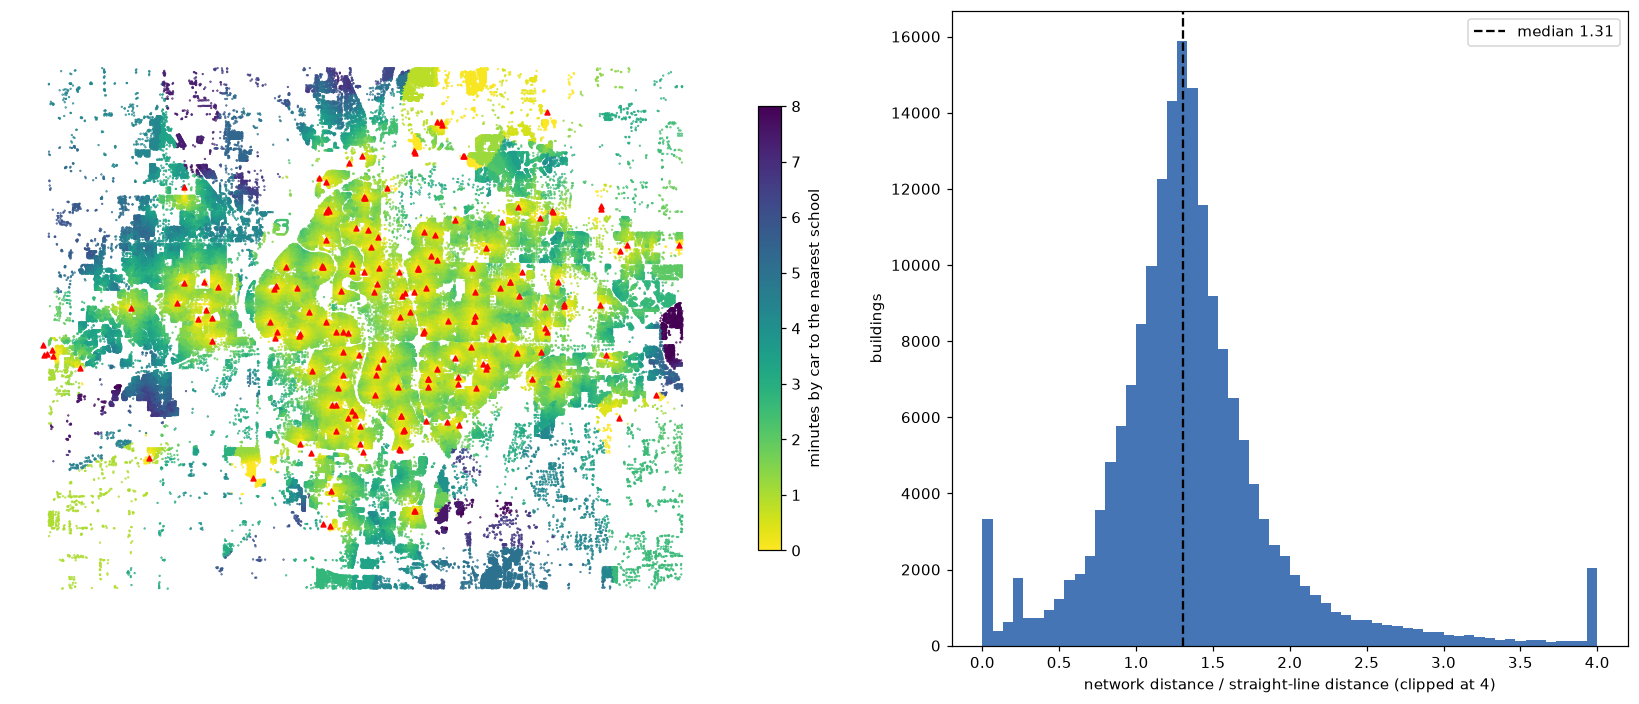

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(15, 6.5), gridspec_kw={"width_ratios": [1.3, 1]})  # map and histogram
sc = ax[0].scatter(bld.geometry.x, bld.geometry.y, c=bld.minutes, s=0.2, cmap="viridis_r", vmax=8)  # buildings by travel time
schools.plot(ax=ax[0], color="r", marker="^", markersize=10)  # schools
plt.colorbar(sc, ax=ax[0], shrink=0.7, label="minutes by car to the nearest school"); ax[0].set_aspect("equal"); ax[0].set_axis_off()  # labels
ax[1].hist(bld.detour.clip(upper=4), bins=60, color="#4575b4")  # detour factor
ax[1].axvline(bld.detour.median(), color="k", ls="--", label=f"median {bld.detour.median():.2f}")  # median
ax[1].set_xlabel("network distance / straight-line distance (clipped at 4)"); ax[1].set_ylabel("buildings"); ax[1].legend()  # labels
plt.tight_layout(); plt.show()  # draw

Most buildings are within a few minutes' drive of a school; the longest times are at the rural
edges of the network. Network distance exceeded the straight line by about a third for the median
building and by much more where rivers, railways and highways force detours. (The small spike at
zero is buildings that snap to the same road node as a school, so their network distance is zero
while the straight line is not.) On the CPU, SciPy's
multi-source Dijkstra handled all schools in one call; cuGraph ran one search per school, and on
a road network of this size the GPU searches were slower, for the reasons given in the Overview.
Both gave identical travel times. While this notebook was written they did not: the network
contains 270 pairs of parallel segments (two roads joining the same two junctions), and cuGraph
kept an arbitrary one of each pair where SciPy keeps the quicker, so some GPU travel times were up
to 0.3 % too long. GeoLattice now passes only the quickest of parallel edges to cuGraph.

## Connected components and what they reveal

The OSMnx network is one connected component. Components become informative when something is
removed: here, all motorway segments and their ramps, as if the freeways were closed.

In [7]:
keep = ~roads.highway.str.contains("motorway")  # drop motorways and their links
g_closed = pdist.network.graph_from_lines(roads[keep])  # graph without them
lab = pdist.network.components(g_closed, compute="gpu" if caps["gpus"] else "cpu")  # component per node
sizes = np.bincount(lab)  # nodes per component
print(f"{g_closed.n_nodes:,} nodes in {len(sizes)} components; largest {sizes.max():,} nodes; "  # summary
      f"{(sizes < 10).sum()} components with fewer than 10 nodes")  # fragments
print("same labels on CPU:", bool((pd.factorize(pdist.network.components(g_closed, compute="cpu"))[0] == pd.factorize(lab)[0]).all()))  # check

15,729 nodes in 2 components; largest 15,727 nodes; 1 components with fewer than 10 nodes
same labels on CPU: True


The network barely changed: without the freeways it still holds together, apart from one
two-node fragment that was reachable only by a ramp. Wichita's street grid offers an alternative
to every freeway, which is itself a useful finding about the network's redundancy. Running components on a raw network
in the same way finds digitizing errors (roads that should meet but do not) before they distort
an accessibility analysis.

## Betweenness centrality on CPU and GPU

Exact betweenness of 16,000 nodes needs a shortest-path tree from every node. NetworkX does it
in pure Python, so the comparison uses a sample of `k` source nodes (the approximation is
unbiased and its error shrinks with `k`); cuGraph also computes the exact version.

In [8]:
t = {}  # timings
t["CPU (NetworkX), k = 500"], b_cpu = timed(lambda: pdist.network.centrality(g, "betweenness", k=500, seed=0, compute="cpu"))  # sampled, CPU
if caps["gpus"]:  # cuGraph
    t["GPU (cuGraph), k = 500"], b_gpu = timed(lambda: pdist.network.centrality(g, "betweenness", k=500, seed=0, compute="gpu"))  # sampled, GPU
    t["GPU (cuGraph), exact"], b_exact = timed(lambda: pdist.network.centrality(g, "betweenness", compute="gpu"))  # all sources
    from scipy.stats import spearmanr  # rank correlation
    print("rank correlation with exact: CPU k=500", round(spearmanr(b_cpu, b_exact)[0], 3),  # sampling error
          "| GPU k=500", round(spearmanr(b_gpu, b_exact)[0], 3))  # same, GPU sample
print(pd.Series(t, name="seconds").round(2).to_string())  # timings

rank correlation with exact: CPU k=500 0.97 | GPU k=500 0.973
CPU (NetworkX), k = 500    16.09
GPU (cuGraph), k = 500      0.28
GPU (cuGraph), exact        3.60


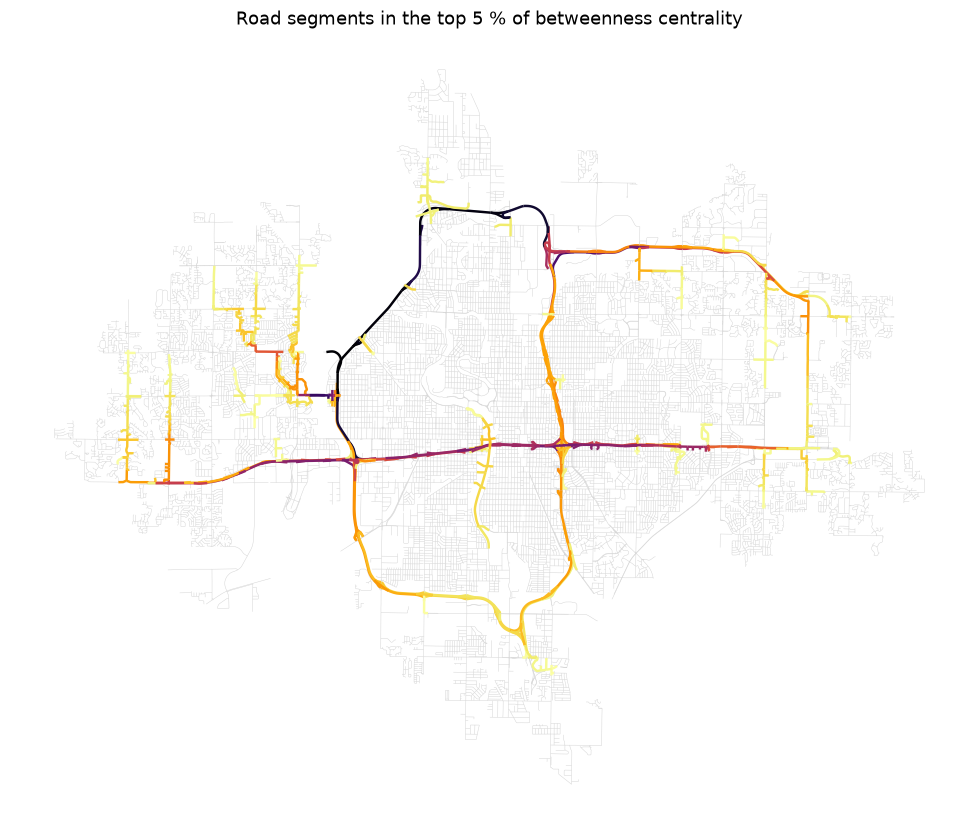

In [9]:
best = b_exact if caps["gpus"] else b_cpu  # the best available estimate
e = roads.copy()  # edges
e["btw"] = np.maximum(best.values[g.src], best.values[g.dst])  # edge score from its end nodes
fig, ax = plt.subplots(figsize=(9, 9))  # one map
e.plot(ax=ax, color="lightgrey", lw=0.3)  # all roads
top = e[e.btw > e.btw.quantile(0.95)]  # the top 5 %
top.plot(ax=ax, column="btw", cmap="inferno_r", lw=1.6)  # coloured by betweenness
ax.set_title("Road segments in the top 5 % of betweenness centrality"); ax.set_axis_off(); plt.tight_layout(); plt.show()  # draw

On this network the GPU computed the exact betweenness about four times faster than NetworkX
computed a 500-node sample, and the sampled values already rank nodes almost like the exact ones (Spearman
correlation 0.97). The highest values trace the freeway loop around central Wichita, the
east-west Kellogg corridor (US 54) and the arterials that feed them: the routes that most
shortest paths share. (This is unweighted
betweenness, counted in hops; it describes the network's structure, not traffic volumes.)

## When the GPU is not used

GeoLattice checks before sending betweenness to cuGraph. `max_shortest_path_count` probes how many
equally short paths connect two distant nodes; above 10^18 cuGraph's 64-bit counters could
overflow and give wrong results, and GeoLattice runs the CPU version with a warning instead. A
regular street lattice is the worst case: the number of shortest paths across an `n x n` grid
grows like the binomial coefficient `C(2n, n)`.

In [10]:
lines = []  # a 70 x 70 lattice of 100 m streets
for i in range(71):  # rows and columns
    for j in range(70):  # segments
        lines.append(shapely.LineString([(j * 100, i * 100), ((j + 1) * 100, i * 100)]))  # east-west segment
        lines.append(shapely.LineString([(i * 100, j * 100), (i * 100, (j + 1) * 100)]))  # north-south segment
grid = pdist.network.graph_from_lines(gpd.GeoDataFrame(geometry=lines, crs=5070))  # the lattice graph
print(f"lattice: {grid.n_nodes:,} nodes | max shortest-path count {pdist.network.max_shortest_path_count(grid):.2e}"  # overflow probe
      f" | Wichita: {pdist.network.max_shortest_path_count(g):.2e}")  # the real network
with _w.catch_warnings(record=True) as caught:  # capture the warning
    _w.simplefilter("always")  # make sure it is recorded
    tb, bl = timed(lambda: pdist.network.centrality(grid, "betweenness", k=200, compute="gpu"))  # asks for the GPU
print(f"{tb:.1f} s;", caught[0].message if caught else "no warning (no GPU on this machine)")  # what happened

lattice: 5,041 nodes | max shortest-path count 9.38e+40 | Wichita: 1.11e+05


1.9 s; Graph has more than 1e18 equal-length shortest paths between some nodes (lattice-like network); cuGraph's int64 path counts would overflow, so betweenness runs on CPU.


The 70 x 70 lattice has about 10^40 equally short corner-to-corner paths, far beyond what a 64-bit
integer holds, so the request for the GPU ran on the CPU with a warning. The Wichita network, with
its irregular blocks, stays far below the limit. Silent overflow would have produced wrong
centralities without any error; checking a cheap bound first is the safer design.

## Summary and exercises

- `graph_from_lines` turns noded road lines into a weighted graph; travel time weights come from
  posted or typical speeds.
- Network distance to the nearest school was a third longer than the straight line for the median
  building, and much longer where barriers force detours.
- A multi-source Dijkstra on the CPU answered accessibility for all 180,000 buildings at once; on a
  road network of this size it beat one cuGraph search per school.
- Removing the freeways isolated only one two-node fragment: the street grid is redundant.
  Component labels find network errors and vulnerable links.
- cuGraph computed exact betweenness four times faster than NetworkX computed a 500-node sample, and the
  sample ranked nodes almost like the exact result.
- On lattice-like networks shortest-path counts overflow 64-bit integers; GeoLattice detects this
  and runs betweenness on the CPU.

**Exercises**

1. Compute travel time to the nearest hospital for every building. What share of buildings is
   more than 10 minutes away?
2. Compare betweenness weighted by travel time (build the NetworkX graph with `g.to_networkx()`
   and pass `weight="weight"`) with the unweighted version. Which roads gain importance?
3. Remove the bridges over the Arkansas River (segments that cross it) and recompute school
   accessibility. Which neighbourhoods lose most?
4. Time exact betweenness on cuGraph for random subgraphs of 2,000, 4,000, 8,000 and 16,000 nodes
   and fit the growth exponent.